In [1]:
from utils import *

In [85]:
a549 = pd.read_csv('/home/qingyuyang/ESM4SL/data/SLKB/cell_line/table/A549.csv')
_, _, gene_count = count_gene_freq(a549)

def visualize_gene_freq(gene_count: dict, max_gene_show: int = 100, show_yval_step: int = 10, show_xlabel_step: int = 5, 
                        plot: bool = False, save_path: Path | None = None, title: str | None = None):
    gene_num = len(gene_count)
    jump = int(gene_num / max_gene_show) if gene_num >= max_gene_show else 1
    sorted_list = sorted(gene_count.items(), key=lambda item: item[1], reverse=True)[::jump]
    keys, values = zip(*sorted_list)
    keys = [gid2name[str(i)] for i in keys]

    fig, ax = plt.subplots(figsize=(20, 8), dpi=400)
    bars = ax.bar(keys, values)
    # for i, bar in enumerate(bars):
    #     if i % show_yval_step == 0:
    #         yval = bar.get_height()
    #         ax.text(bar.get_x() + bar.get_width()/2, yval, int(yval), ha='center', va='bottom')
    # if title:
    #     plt.title(f"{title}")
    plt.ylabel('Number of appearances in SL pairs')
    # ax.get_xaxis().set_visible(False)
    ax.set_xticklabels([])
    # ax.spines['bottom'].set_visible(False)
    # ax.set_xlabel('Genes')
    plt.xlabel('Genes')
    # plt.xticks(np.arange(len(keys))[::show_xlabel_step], keys[::show_xlabel_step], rotation=90)
    if save_path:
        plt.savefig(f"{save_path}/{title}.jpg")
    if not plot:
        plt.clf()
        plt.close(fig)
    else:
        plt.show()

visualize_gene_freq(gene_count, save_path='/home/qingyuyang/ESM4SL/data_preprocess', title='a549_new')

In [17]:
select = a549[(a549['0'] == int(name2id['ADA'])) | (a549['1'] == int(name2id['ADA']))]
print(len(select), len(select[select['2'] == 1]), len(select[select['2'] == 0]))
select

72 0 72


,0,1,2
1942,25,100,0
2014,100,207,0
2015,100,238,0
2016,100,324,0
2017,100,8289,0
...,...,...,...
2080,100,7248,0
2081,100,7298,0
2082,100,7422,0
2083,100,7428,0


In [19]:
gid2protein = pd.read_csv('/home/qingyuyang/ESM4SL/data/mapping/gid2protein.csv')
gid2protein = dict(zip(list(gid2protein['From']), list(gid2protein['Sequence'])))

In [24]:
print(gid2protein[25])
print(gid2protein[100])

MLEICLKLVGCKSKKGLSSSSSCYLEEALQRPVASDFEPQGLSEAARWNSKENLLAGPSENDPNLFVALYDFVASGDNTLSITKGEKLRVLGYNHNGEWCEAQTKNGQGWVPSNYITPVNSLEKHSWYHGPVSRNAAEYLLSSGINGSFLVRESESSPGQRSISLRYEGRVYHYRINTASDGKLYVSSESRFNTLAELVHHHSTVADGLITTLHYPAPKRNKPTVYGVSPNYDKWEMERTDITMKHKLGGGQYGEVYEGVWKKYSLTVAVKTLKEDTMEVEEFLKEAAVMKEIKHPNLVQLLGVCTREPPFYIITEFMTYGNLLDYLRECNRQEVNAVVLLYMATQISSAMEYLEKKNFIHRDLAARNCLVGENHLVKVADFGLSRLMTGDTYTAHAGAKFPIKWTAPESLAYNKFSIKSDVWAFGVLLWEIATYGMSPYPGIDLSQVYELLEKDYRMERPEGCPEKVYELMRACWQWNPSDRPSFAEIHQAFETMFQESSISDEVEKELGKQGVRGAVSTLLQAPELPTKTRTSRRAAEHRDTTDVPEMPHSKGQGESDPLDHEPAVSPLLPRKERGPPEGGLNEDERLLPKDKKTNLFSALIKKKKKTAPTPPKRSSSFREMDGQPERRGAGEEEGRDISNGALAFTPLDTADPAKSPKPSNGAGVPNGALRESGGSGFRSPHLWKKSSTLTSSRLATGEEEGGGSSSKRFLRSCSASCVPHGAKDTEWRSVTLPRDLQSTGRQFDSSTFGGHKSEKPALPRKRAGENRSDQVTRGTVTPPPRLVKKNEEAADEVFKDIMESSPGSSPPNLTPKPLRRQVTVAPASGLPHKEEAGKGSALGTPAAAEPVTPTSKAGSGAPGGTSKGPAEESRVRRHKHSSESPGRDKGKLSRLKPAPPPPPAASAGKAGGKPSQSPSQEAAGEAVLGAKTKATSLVDAVNSDAAKPSQPGEGLKKPVLPATPKPQSAKPSGTPISPAPVPSTLPSASSALAGDQPSST

In [83]:
df = pd.read_csv('/home/qingyuyang/ESM4SL/all_methods_metrics/HS944T_Tail.csv')
df = df[df['Unnamed: 0'].isin(['KG4SL', 'PTGNN', 'ESM4SL'])]
all_nums = np.array([list(df['AUC']), list(df['AUPR']), list(df['BACC'])]).transpose()  #list(df['AUC']), list(df['Precision@20']), list(df['Recall@20'])

mean_values = np.zeros_like(all_nums, dtype=float)
for i in range(all_nums.shape[0]):
    for j in range(all_nums.shape[1]):
        mean_values[i, j] = float(all_nums[i, j].split()[0])

std_values = np.zeros_like(all_nums, dtype=float)
for i in range(all_nums.shape[0]):
    for j in range(all_nums.shape[1]):
        std_values[i, j] = float(all_nums[i, j].split()[1][1:-1])

In [87]:
# mean_values = np.array([[0.5179, 0.1982, 0.1309, 0.5054],
#                         [0.6716, 0.3130, 0.3058, 0.6072],
#                         [0.7823, 0.4384, 0.4424, 0.7246],
#                         [0.7845, 0.4886, 0.5097, 0.7340]])
# std_values = np.array([[0.0283, 0.0174, 0.0726, 0.0148],
#                        [0.0660, 0.0747, 0.0419, 0.0187],
#                        [0.0305, 0.0508, 0.0528, 0.0412],
#                        [0.0431, 0.0506, 0.0331, 0.0356]])
mean_values = np.array([[0.1982, 0.1309],
                        [0.3130, 0.3058],
                        [0.4384, 0.4424],
                        [0.4886, 0.5097]])
std_values = np.array([[0.0174, 0.0726],
                       [0.0747, 0.0419],
                       [0.0508, 0.0528],
                       [0.0506, 0.0331]])

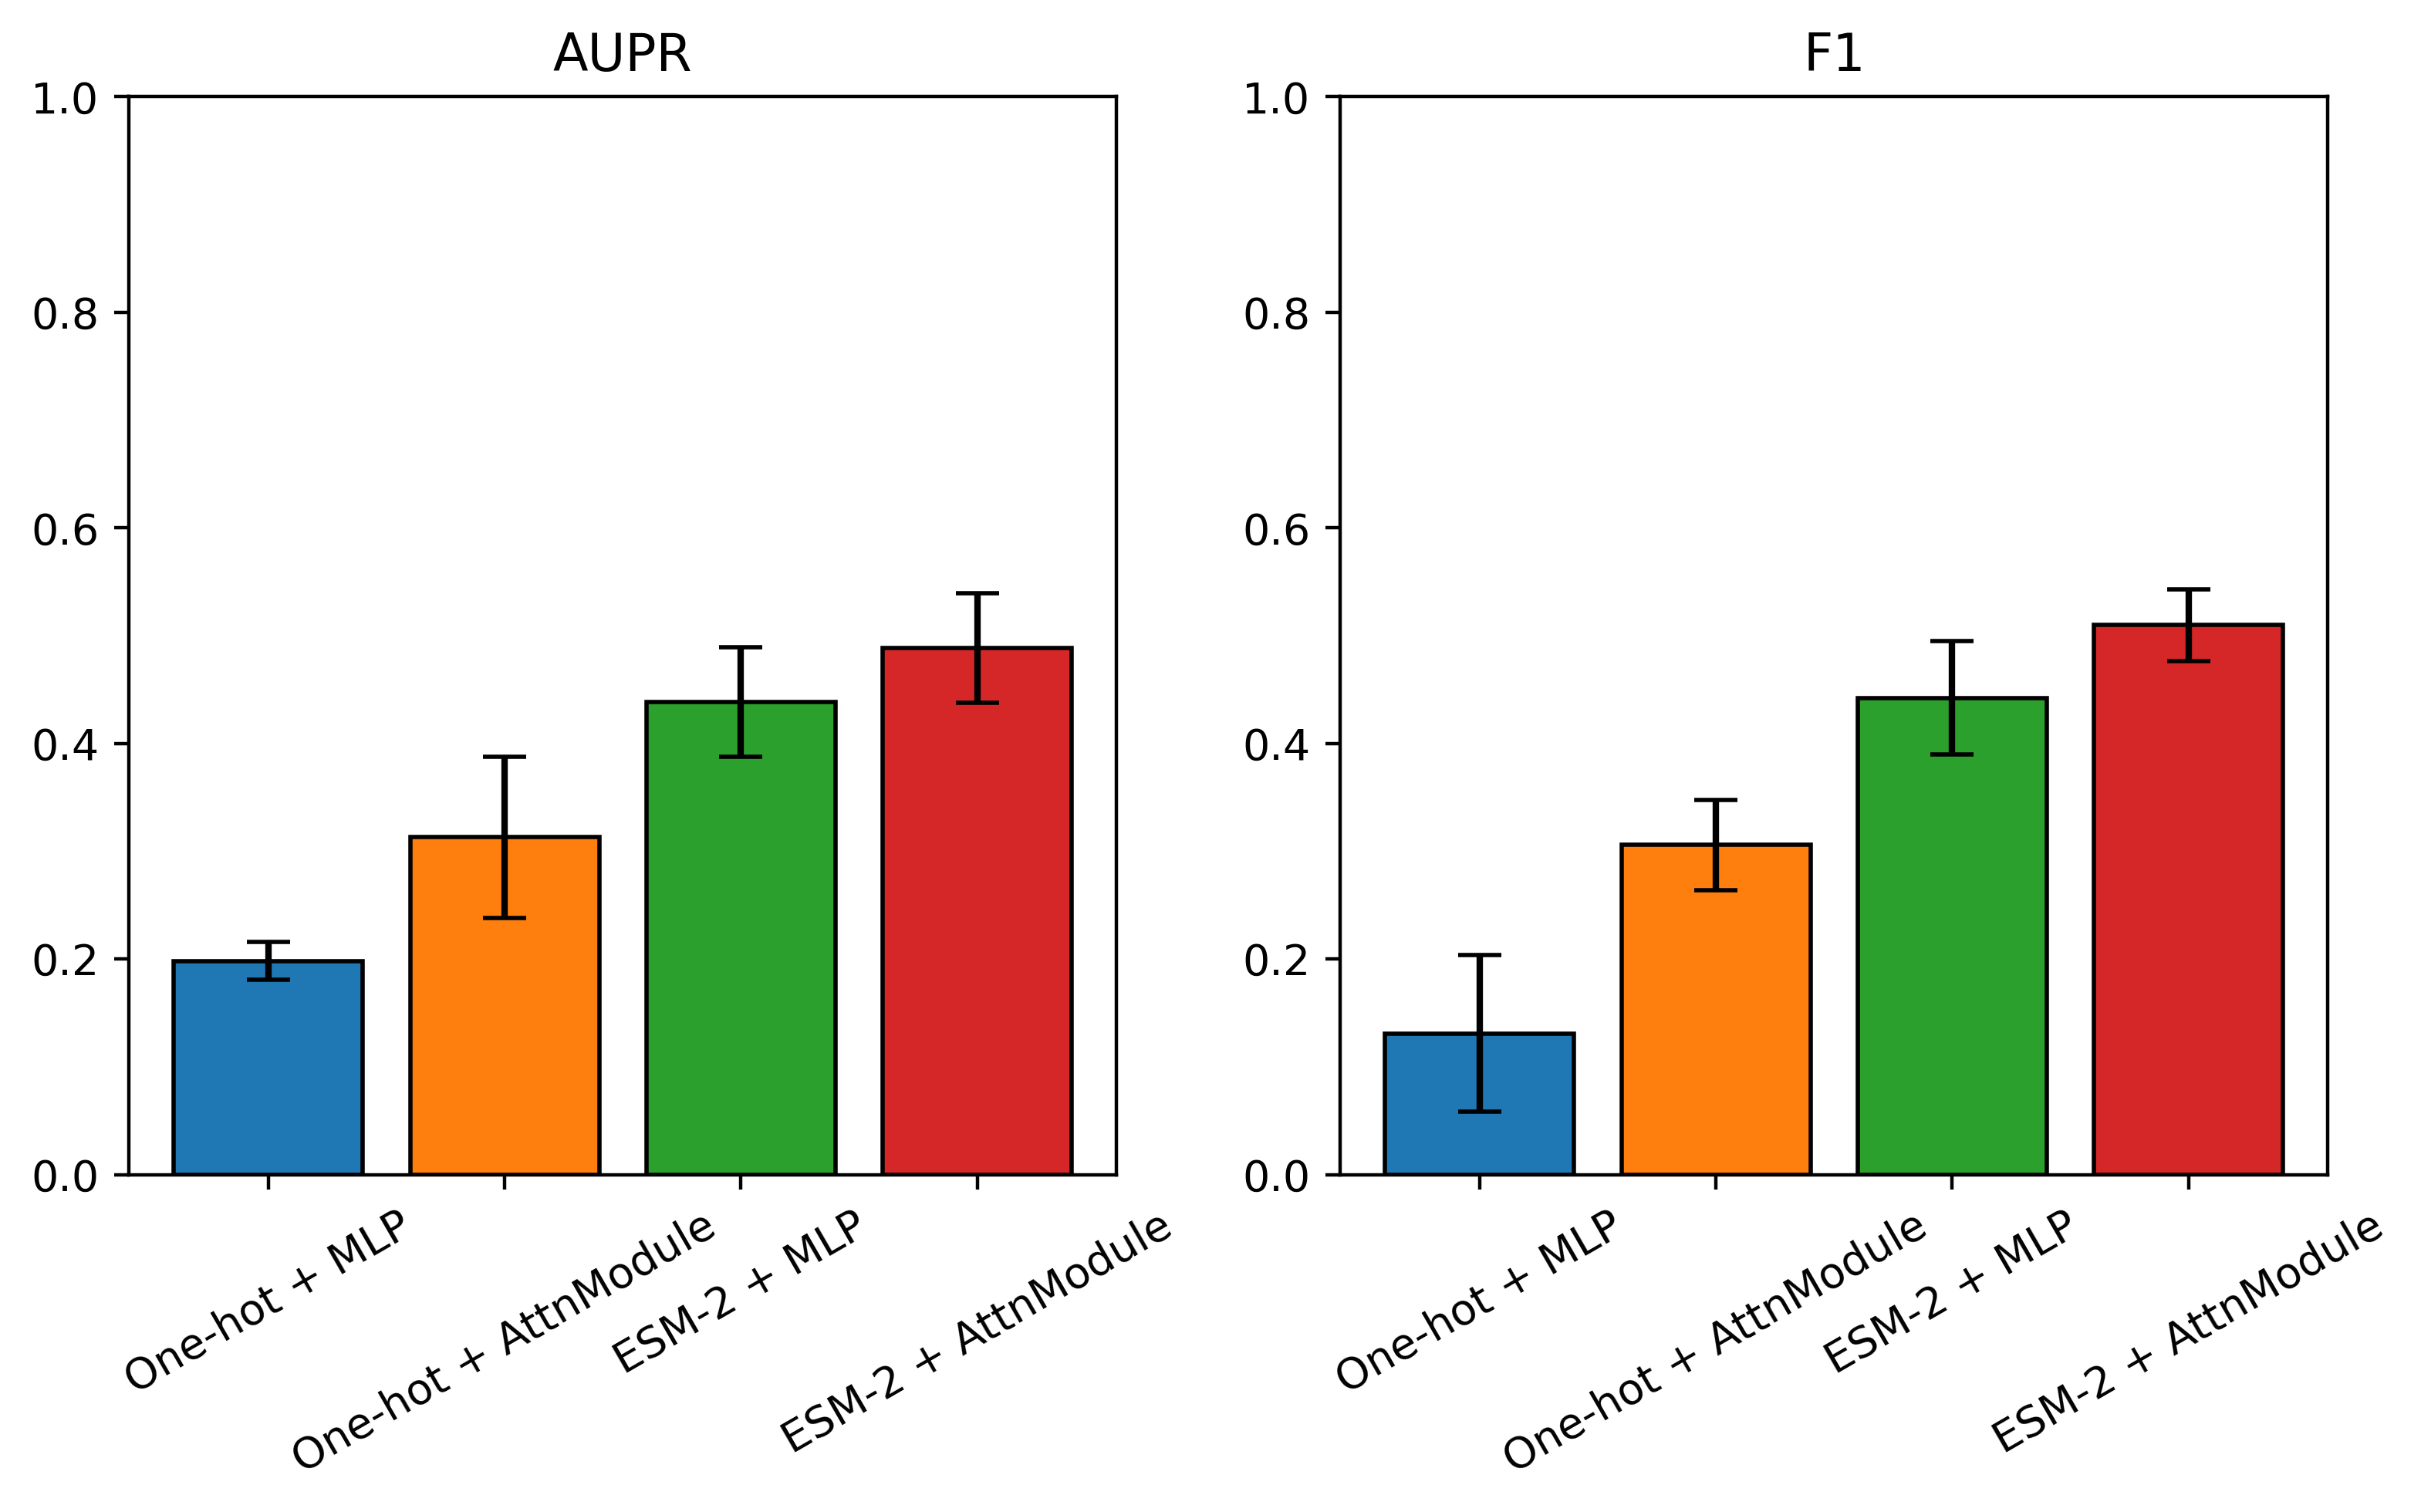

In [89]:
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# 假设我们有以下数据
methods = ['One-hot + MLP', 'One-hot + AttnModule', 'ESM-2 + MLP', 'ESM-2 + AttnModule']
indicators = ['AUPR', 'F1'] #'AUC', , 'Precision@20', 'Recall@20'

# 为每种方法指定不同的颜色
colors = plt.cm.tab10.colors  # 选择一个调色板，tab10有10种颜色，适合7种方法

# 创建图形，6行1列的子图
fig, axes = plt.subplots(1, 2, figsize=(8, 5), dpi=400)
axes = axes.flatten()  # 将二维的axes数组变成一维，方便索引

# 绘制每个指标的柱状图
for i, indicator in enumerate(indicators):
    ax = axes[i]
    
    # 绘制带误差条的柱状图，每个方法的柱子使用不同的颜色
    ax.bar(methods, mean_values[:, i], yerr=std_values[:, i], capsize=5, color=colors[:len(methods)], edgecolor='black')
    
    # 设置图形标题和标签
    ax.set_title(f'{indicator}')
    # ax.set_xlabel('Method')
    ax.set_xticklabels(methods, rotation=30)#, ha='right'
    # ax.set_ylabel(f'{indicator}')
    
    # 设置y轴范围，使得所有子图的y轴范围一致
    ax.set_ylim(0, 1)

# 调整布局，防止标签重叠
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# 假设我们有以下数据
methods = list(df['Unnamed: 0'])
indicators = ['AUC', 'AUPR', 'BACC'] #'AUC', , 'Precision@20', 'Recall@20'

# 为每种方法指定不同的颜色
colors = plt.cm.tab10.colors  # 选择一个调色板，tab10有10种颜色，适合7种方法

# 创建图形，6行1列的子图
fig, axes = plt.subplots(1, 3, figsize=(8, 5), dpi=400)
axes = axes.flatten()  # 将二维的axes数组变成一维，方便索引

# 绘制每个指标的柱状图
for i, indicator in enumerate(indicators):
    ax = axes[i]
    
    # 绘制带误差条的柱状图，每个方法的柱子使用不同的颜色
    ax.bar(methods, mean_values[:, i], yerr=std_values[:, i], capsize=5, color=colors[:len(methods)], edgecolor='black')
    
    # 设置图形标题和标签
    ax.set_title(f'{indicator}')
    # ax.set_xlabel('Method')
    ax.set_xticklabels(methods, rotation=30)#, ha='right'
    # ax.set_ylabel(f'{indicator}')
    
    # 设置y轴范围，使得所有子图的y轴范围一致
    ax.set_ylim(0, 1)

# 调整布局，防止标签重叠
plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re

In [15]:
res1000 = pd.read_csv('/home/qingyuyang/ESM4SL/output/attn/MELJUSO/C2_1000/results.csv')
res1000 = res1000.iloc[-1]
res1000['Unnamed: 0'] = 1000
res1500 = pd.read_csv('/home/qingyuyang/ESM4SL/output/attn/MELJUSO/C2_1500/results.csv')
res1500 = res1500.iloc[-1]
res1500['Unnamed: 0'] = 1500
res2000 = pd.read_csv('/home/qingyuyang/ESM4SL/all_methods_metrics/MELJUSO_C2.csv')
res2000 = res2000.iloc[-1]
res2000['Unnamed: 0'] = 2000
df = pd.concat([res1000, res1500, res2000], axis=1, ignore_index=True).transpose()
# df.index = df['Unnamed: 0']
df

,Unnamed: 0,Accuracy,Precision,Recall,AUC,AUPR,F1,BACC,Precision@10,Precision@20,Recall@10,Recall@20,NDCG@10,NDCG@20,Sum6
0,1000,0.8614 (0.0242),0.4637 (0.0819),0.5499 (0.1224),0.7927 (0.0402),0.4780 (0.1098),0.4974 (0.0856),0.7277 (0.0562),NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1500,0.7717 (0.2016),0.3936 (0.1322),0.5217 (0.1986),0.7720 (0.0201),0.4390 (0.0600),0.4065 (0.0816),0.6630 (0.0576),NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2000,0.8642 (0.0280),0.4861 (0.0656),0.5604 (0.1151),0.7845 (0.0431),0.4886 (0.0506),0.5097 (0.0331),0.7340 (0.0356),0.7000 (0.1225),0.7000 (0.0500),1.0000 (0.0000),1.0000 (0.0000),0.8903 (0.1141),0.8931 (0.0777),4.2168


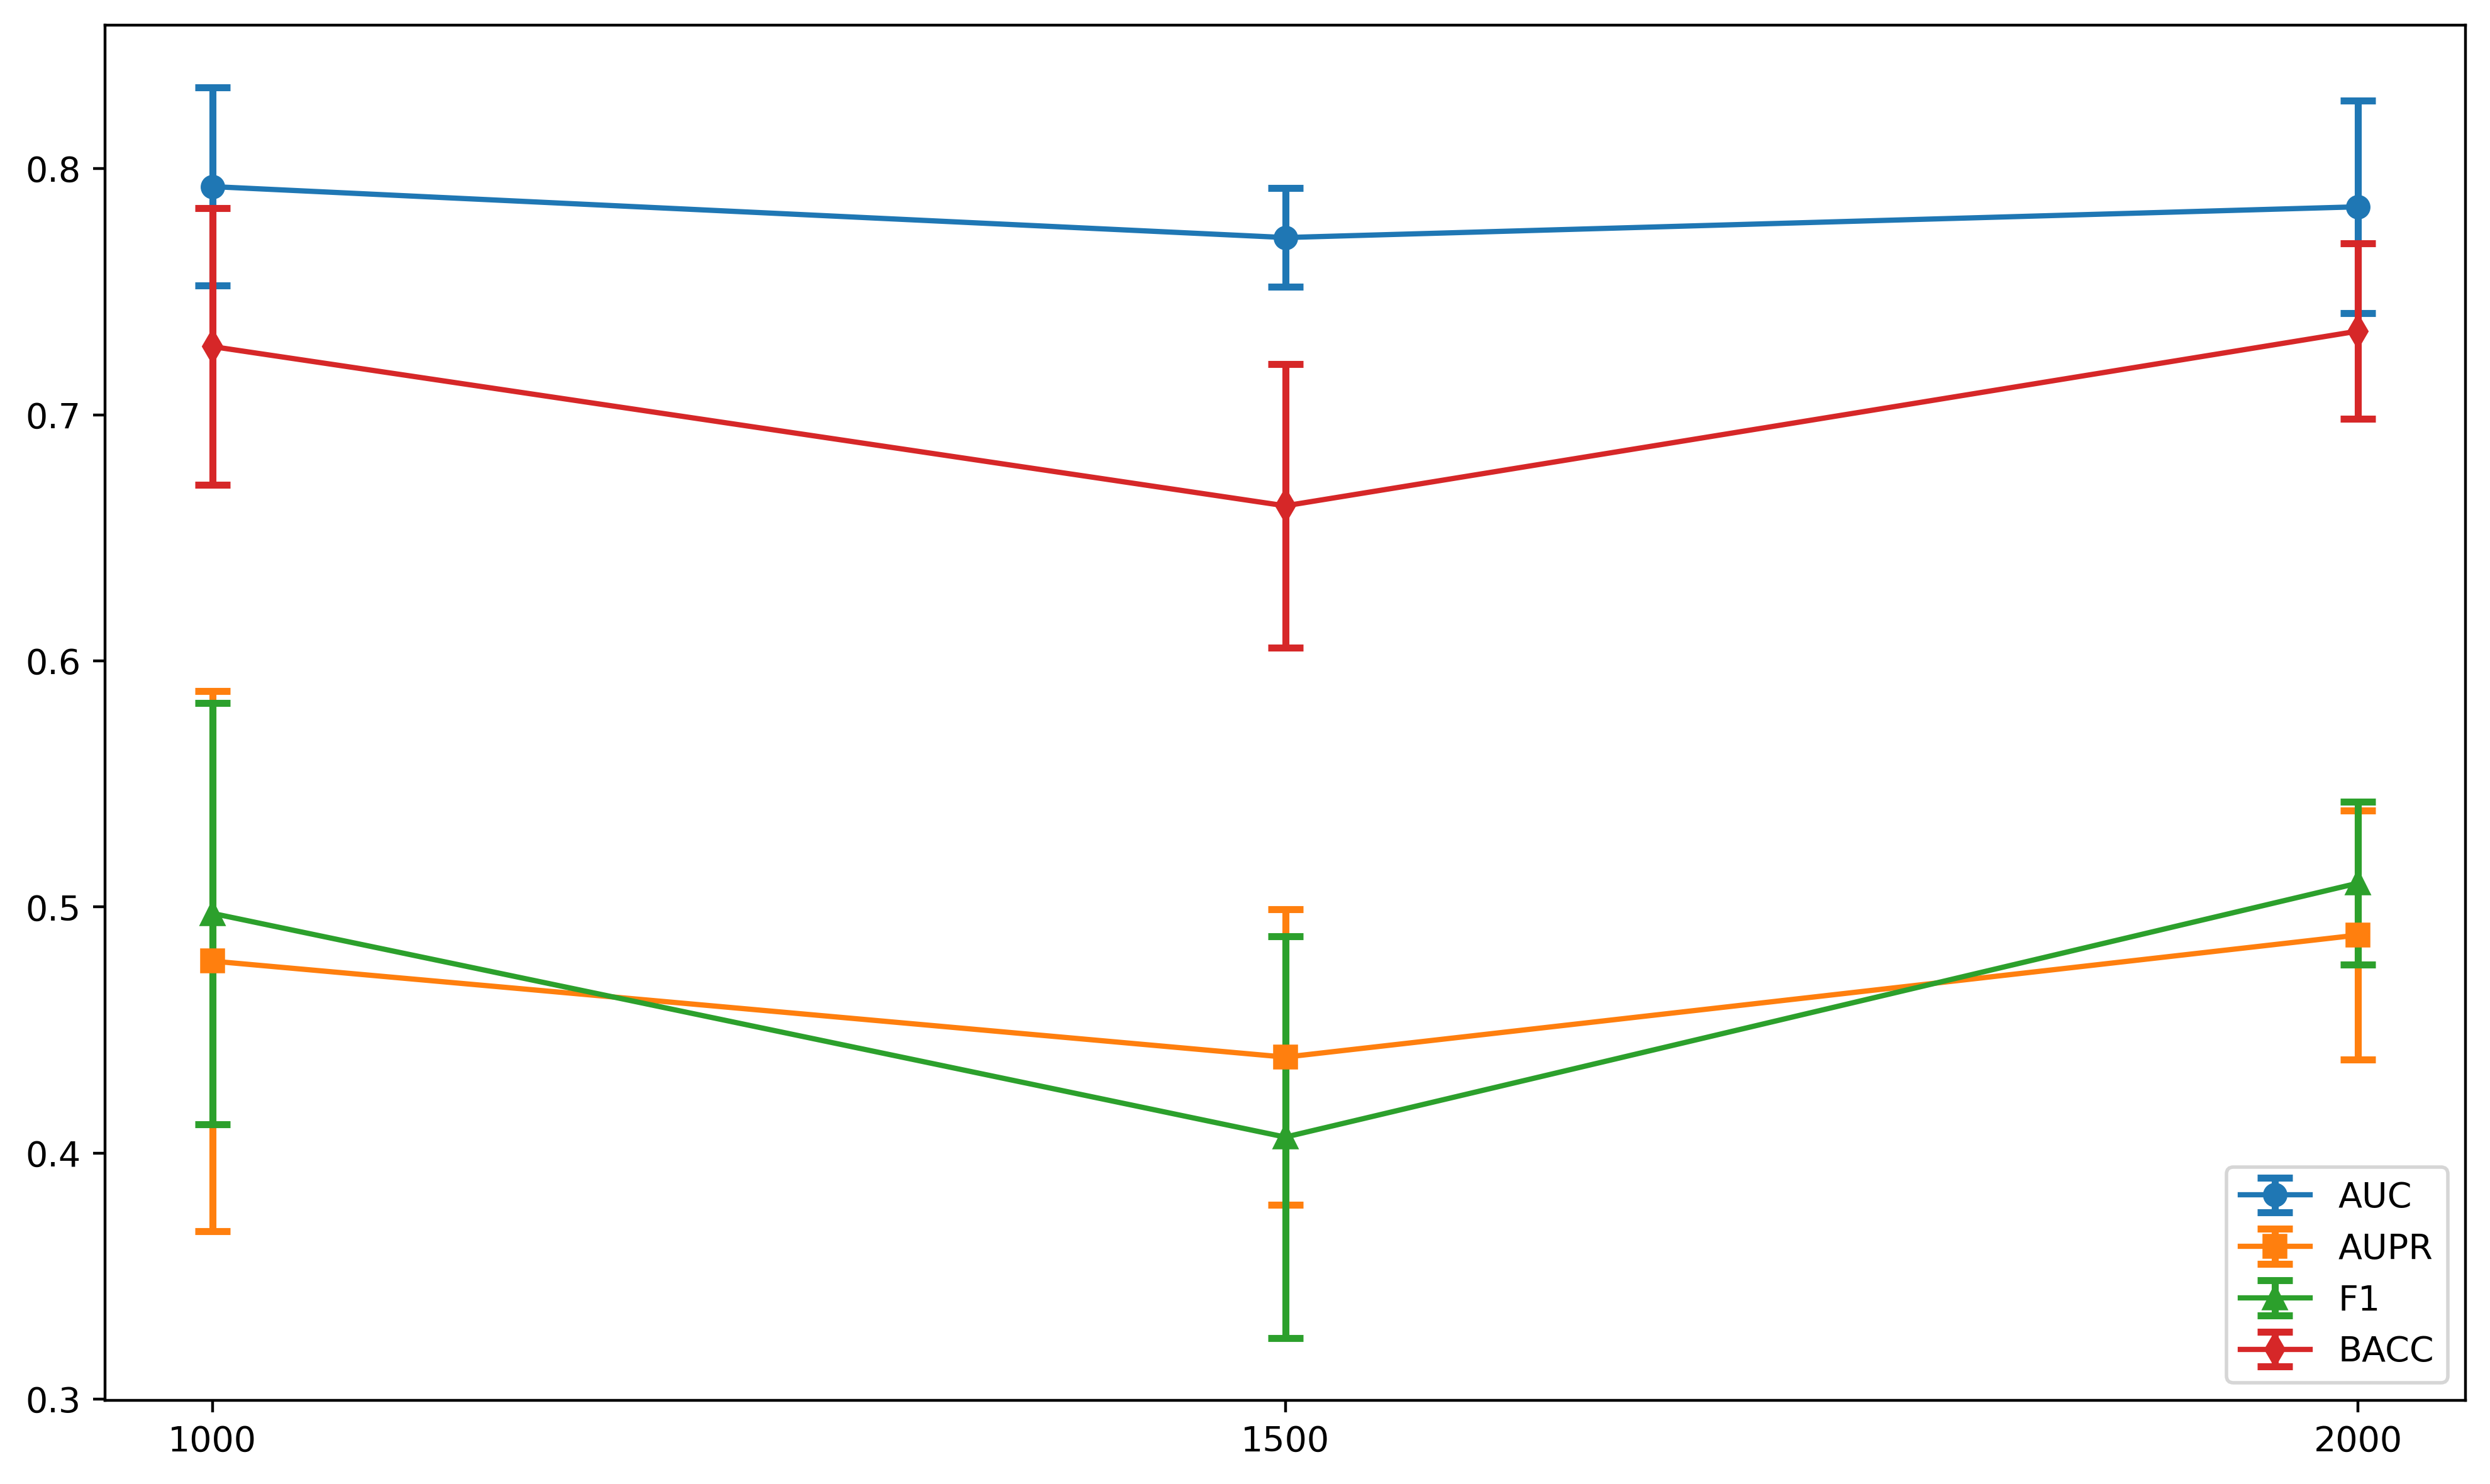

In [20]:
# 读取 CSV 文件
# df = pd.read_csv('/home/qingyuyang/ESM4SL/data/ebd.csv', index_col=0)

indices = list(df['Unnamed: 0'])

# 定义一个函数用于从 "mean (std)" 格式的字符串中提取均值和标准差
def extract_mean_std(value_str):
    match = re.match(r'([0-9.]+) \(([0-9.]+)\)', value_str)
    if match:
        mean = float(match.group(1))
        std = float(match.group(2))
        return mean, std
    else:
        return np.nan, np.nan  # 如果无法匹配，则返回 NaN

# 对 AUC, AUPR, F1, BACC 列应用上述函数，提取均值和标准差
for col in ['AUC', 'AUPR', 'F1', 'BACC']:
    df[col + ' (mean)'], df[col + ' (std)'] = zip(*df[col].apply(extract_mean_std))

# 创建一个图形
plt.figure(figsize=(10, 6), dpi=400)

# 绘制每个指标的折线图
plt.errorbar(indices, df['AUC (mean)'], yerr=df['AUC (std)'], label='AUC', fmt='-o', capsize=5, capthick=2, elinewidth=2)
plt.errorbar(indices, df['AUPR (mean)'], yerr=df['AUPR (std)'], label='AUPR', fmt='-s', capsize=5, capthick=2, elinewidth=2)
plt.errorbar(indices, df['F1 (mean)'], yerr=df['F1 (std)'], label='F1', fmt='-^', capsize=5, capthick=2, elinewidth=2)
plt.errorbar(indices, df['BACC (mean)'], yerr=df['BACC (std)'], label='BACC', fmt='-d', capsize=5, capthick=2, elinewidth=2)

# 设置图形标签和标题
# plt.xlabel('embed_dim')
# plt.ylabel('results')
# plt.title('参数敏感性实验结果')
plt.legend()
# plt.xscale('log')
plt.xticks(indices)
# 显示图形
plt.tight_layout()
plt.show()